# Элементарные методы прогнозирования: MA, EMA, DEMA, TEMA

**Задача.** Реализовать скользящее среднее (MA), экспоненциальное сглаживание (EMA), двойное (DEMA, метод Хольта) и тройное (TEMA, метод Хольта–Винтерса) экспоненциальное сглаживание, подобрать параметры и сравнить качество прогноза на нестационарном и стационарном рядах.

**Данные.** Месячные ряды из `../data/`: число авиапассажиров (нестационарный: тренд + сезонность) и среднемесячная температура (стационарный по уровню, с сезонностью).

**План.**
1. Реализация четырёх методов «с нуля» и визуализация прогнозов с фиксированными параметрами.
2. Отложенный тест — последние 5 точек каждого ряда.
3. Подбор параметров перебором по сетке на **валидации внутри обучающей части** (скользящее начало прогноза, 3 окна по 5 точек), затем однократная оценка на тесте.
4. Для сравнения — «оптимистичная» оценка при подборе параметров прямо на тестовых 5 точках (так было сделано в первой версии работы).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error as mae

%matplotlib inline

DATA_DIR = '../data/'

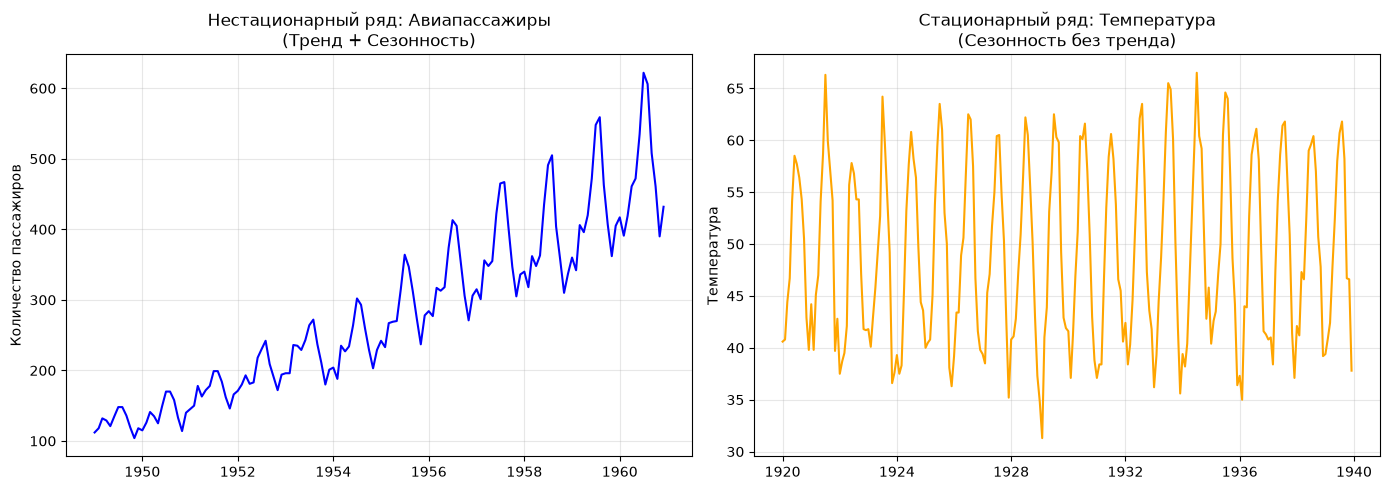

In [2]:
passengers = pd.read_csv(DATA_DIR + 'international-airline-passengers.csv', parse_dates=['Month'], index_col='Month')
temperature = pd.read_csv(DATA_DIR + 'mean-monthly-air-temperature-deg.csv', parse_dates=['Month'], index_col='Month')

# Переименуем столбцы для удобства
passengers.columns = ['Count']
temperature.columns = ['Deg']

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(passengers, color='blue')
axes[0].set_title('Нестационарный ряд: Авиапассажиры\n(Тренд + Сезонность)')
axes[0].set_ylabel('Количество пассажиров')
axes[0].grid(True, alpha=0.3)

axes[1].plot(temperature, color='orange')
axes[1].set_title('Стационарный ряд: Температура\n(Сезонность без тренда)')
axes[1].set_ylabel('Температура')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [3]:
df_air, df_temp = passengers, temperature

series_air = df_air['Count']
series_temp = df_temp['Deg']

n_preds = 5

In [4]:
# --- Функции моделей ---

def predict_ma(series, window, n_pred):
    s = pd.Series(series).copy()
    for _ in range(n_pred):
        next_val = s.iloc[-window:].mean()
        s = pd.concat([s, pd.Series([next_val])], ignore_index=True)
    return s

def predict_ema(series, alpha, n_pred):
    s = pd.Series(series).reset_index(drop=True)
    result = [s.iloc[0]]
    for val in s.iloc[1:]:
        result.append(alpha * val + (1 - alpha) * result[-1])
    for _ in range(n_pred):
        result.append(result[-1])  # плоский прогноз
    return pd.Series(result)

def predict_dema(series, alpha, beta, n_pred):
    s = pd.Series(series).reset_index(drop=True)
    result = [s.iloc[0]]
    level, trend = s.iloc[0], s.iloc[1] - s.iloc[0]
    for val in s.iloc[1:]:
        last_level = level
        level = alpha * val + (1 - alpha) * (level + trend)
        trend = beta * (level - last_level) + (1 - beta) * trend
        result.append(level + trend)
    for _ in range(n_pred):
        result.append(level + trend)  # прогноз: уровень + тренд
    return pd.Series(result)

def predict_tema(series, alpha, beta, gamma, slen, n_pred):
    s = pd.Series(series).copy()
    seasonals = np.zeros(slen)
    for i in range(slen):
        seasonals[i] = s.iloc[i] - s.iloc[:slen].mean()

    # Проверка: сезонный период должен быть строго меньше длины ряда
    if slen >= len(series):
        raise ValueError(f"slen={slen} должно быть строго меньше длины ряда len={len(series)}")

    result = []
    level = s.iloc[0]
    trend = (s.iloc[slen] - s.iloc[0]) / slen

    for i in range(len(s)):
        val = s.iloc[i]
        if i == 0:
            result.append(val)
            continue
        last_level = level
        level = alpha * (val - seasonals[i % slen]) + (1 - alpha) * (level + trend)
        trend = beta * (level - last_level) + (1 - beta) * trend
        seasonals[i % slen] = gamma * (val - level) + (1 - gamma) * seasonals[i % slen]
        result.append(level + trend + seasonals[i % slen])

    for m in range(1, n_pred + 1):
        val_pred = level + m * trend + seasonals[(len(s) + m - 1) % slen]
        result.append(val_pred)
    return pd.Series(result)

### Прогнозы с фиксированными (неподобранными) параметрами

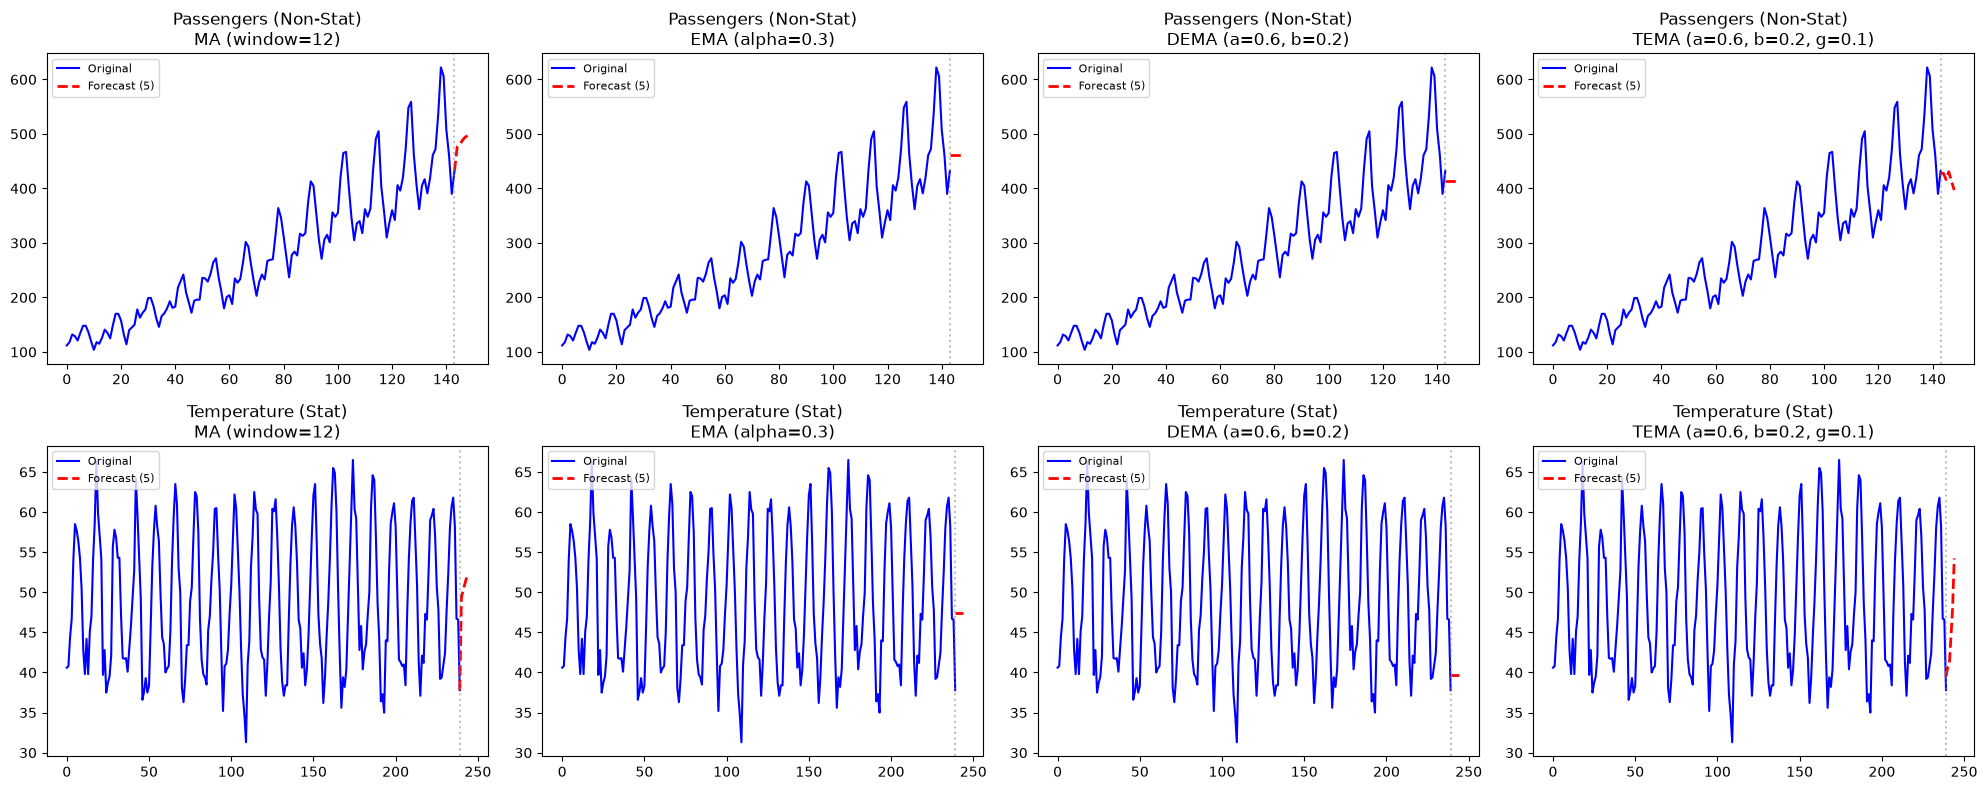

In [5]:
# Визуализация
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
titles = ["MA (window=12)", "EMA (alpha=0.3)", "DEMA (a=0.6, b=0.2)", "TEMA (a=0.6, b=0.2, g=0.1)"]

for row, (name, series) in enumerate([("Passengers (Non-Stat)", series_air), ("Temperature (Stat)", series_temp)]):
    # Сезонный период (slen). Для месячных данных это 12.
    slen = 12

    preds_ma = predict_ma(series, window=slen, n_pred=n_preds)
    preds_ema = predict_ema(series, alpha=0.3, n_pred=n_preds)
    preds_dema = predict_dema(series, alpha=0.6, beta=0.2, n_pred=n_preds)
    preds_tema = predict_tema(series, alpha=0.6, beta=0.2, gamma=0.1, slen=slen, n_pred=n_preds)

    preds_list = [preds_ma, preds_ema, preds_dema, preds_tema]

    for col, (title, preds) in enumerate(zip(titles, preds_list)):
        ax = axes[row, col]

        # Оригинальные данные
        ax.plot(range(len(series)), series.values, color='blue', label='Original')

        # Прогноз (последние n_preds точек + оригинал для связи)
        x_pred = range(len(series) - 1, len(series) + n_preds)
        y_pred = preds.iloc[-(n_preds + 1):].values
        ax.plot(x_pred, y_pred, color='red', linestyle='--', linewidth=2, label=f'Forecast ({n_preds})')

        ax.axvline(len(series) - 1, color='gray', linestyle=':', alpha=0.5)
        ax.set_title(f"{name}\n{title}")
        ax.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

### Разбиение: отложенный тест — последние 5 месяцев

In [6]:
# Разделение на обучающую и тестовую выборки (последние 5 месяцев для прогноза)
train_pass, test_pass = df_air['Count'][:-5], df_air['Count'][-5:]
train_temp, test_temp = df_temp['Deg'][:-5], df_temp['Deg'][-5:]

print(f"--- Авиапассажиры ---")
print(f"Размер train: {len(train_pass)}, test: {len(test_pass)}")
print(f"Истинные значения для прогноза (test): {test_pass.values}\n")

print(f"--- Температура ---")
print(f"Размер train: {len(train_temp)}, test: {len(test_temp)}")
print(f"Истинные значения для прогноза (test): {test_temp.values}")

--- Авиапассажиры ---
Размер train: 139, test: 5
Истинные значения для прогноза (test): [606 508 461 390 432]

--- Температура ---
Размер train: 235, test: 5
Истинные значения для прогноза (test): [61.8 58.2 46.7 46.6 37.8]


### Подбор параметров на валидации

Параметры выбираются по средней MAE на трёх последовательных окнах по 5 точек в конце обучающей части (rolling origin: модель каждый раз видит только прошлое относительно окна). Тестовые 5 точек в подборе не участвуют. Сетки параметров те же, что и в первой версии работы.

In [7]:
H = 5          # горизонт прогноза
N_FOLDS = 3    # число валидационных окон
SLEN = 12      # сезонный период

# Сетки параметров для каждого метода: name -> (функция прогноза, список параметров)
grid = {
    'MA':   (lambda s, p, h: predict_ma(s, p, h), list(range(3, 25))),
    'EMA':  (lambda s, p, h: predict_ema(s, p, h), [float(round(a, 2)) for a in np.arange(0.05, 1.0, 0.05)]),
    'DEMA': (lambda s, p, h: predict_dema(s, *p, h),
             [(float(round(a, 1)), float(round(b, 1))) for a in np.arange(0.1, 1.0, 0.1) for b in np.arange(0.1, 1.0, 0.1)]),
    'TEMA': (lambda s, p, h: predict_tema(s, *p, SLEN, h),
             [(float(round(a, 1)), float(round(b, 1)), float(round(g, 1)))
              for a in np.arange(0.1, 0.9, 0.2) for b in np.arange(0.1, 0.9, 0.2) for g in np.arange(0.1, 0.9, 0.2)]),
}


def forecast(name, series, params, h):
    fn = grid[name][0]
    return fn(series, params, h).iloc[-h:].values


def validation_mae(name, series_train, params, h=H, n_folds=N_FOLDS):
    """Средняя MAE по n_folds последовательным окнам длины h в конце обучающей части."""
    n = len(series_train)
    errs = []
    for k in range(n_folds, 0, -1):
        tr = series_train.iloc[:n - k * h]
        va = series_train.iloc[n - k * h: n - (k - 1) * h]
        errs.append(mae(va.values, forecast(name, tr, params, h)))
    return float(np.mean(errs))


def tune_and_evaluate(series_train, series_test):
    rows = []
    for name, (_, params_list) in grid.items():
        # честный подбор: по валидации внутри train
        val_scores = {p: validation_mae(name, series_train, p) for p in params_list}
        best_p = min(val_scores, key=val_scores.get)
        test_mae = mae(series_test.values, forecast(name, series_train, best_p, len(series_test)))
        # "оптимистичный" подбор прямо на тесте (как в первой версии работы) — только для сравнения
        test_scores = {p: mae(series_test.values, forecast(name, series_train, p, len(series_test)))
                       for p in params_list}
        oracle_p = min(test_scores, key=test_scores.get)
        rows.append({'Модель': name,
                     'Параметры (валидация)': best_p, 'MAE валидация': val_scores[best_p], 'MAE тест': test_mae,
                     'Параметры (подбор на тесте)': oracle_p, 'MAE тест (подбор на тесте)': test_scores[oracle_p]})
    return pd.DataFrame(rows).set_index('Модель')


res_air = tune_and_evaluate(train_pass, test_pass)
res_temp = tune_and_evaluate(train_temp, test_temp)

In [8]:
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 10)

print('=== Авиапассажиры (нестационарный ряд) ===')
print(res_air.round(2).to_string())
print()
print('=== Температура (стационарный ряд) ===')
print(res_temp.round(2).to_string())

=== Авиапассажиры (нестационарный ряд) ===
       Параметры (валидация)  MAE валидация  MAE тест Параметры (подбор на тесте)  MAE тест (подбор на тесте)
Модель                                                                                                       
MA                        14          64.92     53.15                          14                       53.15
EMA                      0.1          78.01     59.87                         0.1                       59.87
DEMA              (0.8, 0.9)          70.98    215.22                  (0.1, 0.9)                       58.42
TEMA         (0.3, 0.3, 0.7)          13.65      7.60             (0.3, 0.3, 0.7)                        7.60

=== Температура (стационарный ряд) ===
       Параметры (валидация)  MAE валидация  MAE тест Параметры (подбор на тесте)  MAE тест (подбор на тесте)
Модель                                                                                                       
MA                        14         

In [9]:
def best_model(res):
    name = res['MAE валидация'].idxmin()   # выбор модели — тоже по валидации
    return name, res.loc[name, 'Параметры (валидация)'], res.loc[name, 'MAE тест']

for title, res in [('Авиапассажиров', res_air), ('Температуры', res_temp)]:
    name, params, test_err = best_model(res)
    print(f"Лучшая по валидации модель для {title}: {name}, параметры {params}, MAE на тесте = {test_err:.2f}")

Лучшая по валидации модель для Авиапассажиров: TEMA, параметры (0.3, 0.3, 0.7), MAE на тесте = 7.60
Лучшая по валидации модель для Температуры: TEMA, параметры (0.1, 0.5, 0.5), MAE на тесте = 1.67


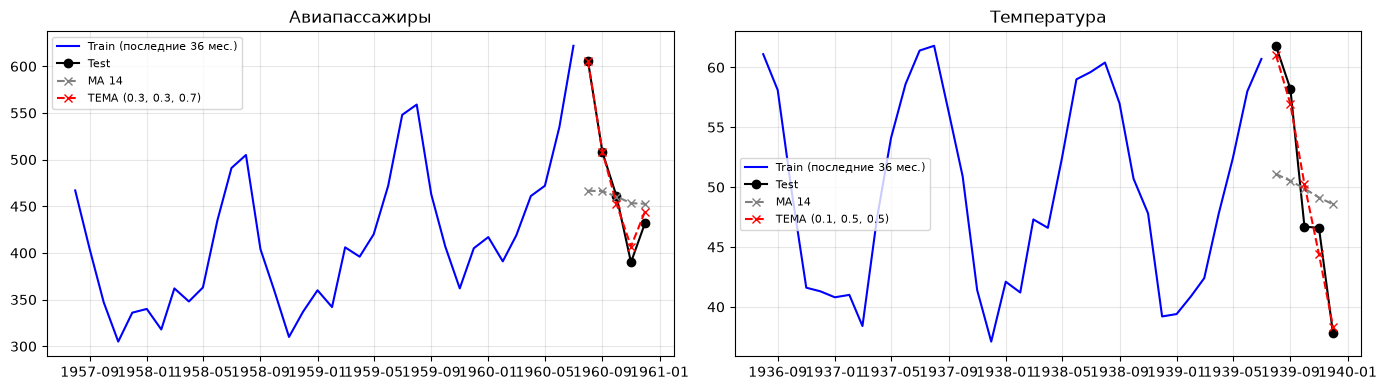

In [10]:
# Прогноз лучших (по валидации) моделей на тестовом отрезке
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (title, tr, te, res) in zip(axes, [('Авиапассажиры', train_pass, test_pass, res_air),
                                            ('Температура', train_temp, test_temp, res_temp)]):
    ax.plot(tr.index[-36:], tr.values[-36:], color='blue', label='Train (последние 36 мес.)')
    ax.plot(te.index, te.values, color='black', marker='o', label='Test')
    for name, color in [('MA', 'gray'), ('TEMA', 'red')]:
        p = res.loc[name, 'Параметры (валидация)']
        ax.plot(te.index, forecast(name, tr, p, len(te)), linestyle='--', marker='x', color=color,
                label=f'{name} {p}')
    ax.set_title(title)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Выводы

| Модель | Авиапассажиры: параметры (валидация) | MAE тест | MAE тест при подборе на тесте | Температура: параметры (валидация) | MAE тест | MAE тест при подборе на тесте |
|---|---|---|---|---|---|---|
| MA | w=14 | 53.15 | 53.15 | w=14 | 6.97 | 6.82 |
| EMA | α=0.1 | 59.87 | 59.87 | α=0.05 | 7.74 | 7.74 |
| DEMA | α=0.8, β=0.9 | 215.22 | 58.42 | α=0.1, β=0.1 | 7.83 | 7.21 |
| TEMA | α=0.3, β=0.3, γ=0.7 | **7.60** | 7.60 | α=0.1, β=0.5, γ=0.5 | **1.67** | 1.42 |

**1. Авиапассажиры (нестационарный ряд).** Явный восходящий тренд (рост примерно со 100 до 600 тыс. за 12 лет) и годовая сезонность, амплитуда которой растёт вместе с уровнем.
- MA и EMA дают плоский прогноз и не учитывают ни тренд, ни сезонность.
- DEMA учитывает тренд, но не сезонность: параметры, выбранные на валидации, экстраполируют локальный рост и на тестовом сезонном спаде ошибаются сильнее всех (MAE 215.22). При подборе прямо на тесте DEMA выглядела бы приемлемо (58.42) — наглядный пример того, насколько оптимистична оценка «подбор на тесте».
- TEMA (метод Хольта–Винтерса) — единственная из четырёх моделей, явно описывающая уровень, тренд и сезонность; на тесте MAE 7.60, и параметры, выбранные на валидации, совпали с оптимальными на тесте.

**2. Температура (стационарный по уровню ряд с сезонностью).** Колеблется около ~50°F без тренда, амплитуда сезонных колебаний почти постоянна.
- MA, EMA и DEMA усредняют сезонность и дают MAE около 7–8.
- TEMA снова лучшая (MAE 1.67 против 1.42 при «подсмотренных» параметрах) — выигрыш даёт сезонная компонента.

**3. Общий вывод.** Для обоих месячных рядов с периодом сезонности 12 лучшей по валидации и на тесте оказалась TEMA; MA/EMA/DEMA имеют смысл для рядов без выраженной сезонности. Честный подбор параметров на валидации практически не изменил результат TEMA, но для DEMA разница между честной и «оптимистичной» оценкой огромна.

**Ограничения.** Тест — всего 5 точек, валидация — 3 окна по 5 точек, поэтому различия в десятые доли MAE статистически ненадёжны. TEMA реализована в аддитивном варианте; для пассажиров с растущей амплитудой естественнее мультипликативная сезонность или логарифмирование ряда.